In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('../data/Food_Delivery_Time_Prediction.csv')

df.head()

,Order_ID,Order_Date,Order_Hour,Day_of_Week,Is_Weekend,Is_Festival,Weather,Pickup_Zone,Dropoff_Zone,Vehicle_Type,...,Order_Items,Restaurant_Load,Preparation_Time_Min,Road_Distance_km,Delivery_Distance_Category,Traffic_Level,Number_of_Signals,Average_Speed_kmph,Delivery_Priority,Time_taken_min
0,ORD000001,2025-10-28,8,Tuesday,0,0,Clear,CBD,Commercial,Scooter,...,1,Medium,23,30.55,Long,Moderate,15,28.7,Normal,91
1,ORD000002,2025-09-26,12,Friday,0,0,Rain,CBD,CBD,Scooter,...,3,Medium,11,2.25,Short,Moderate,17,23.3,Normal,21
2,ORD000003,2025-01-26,18,Sunday,1,0,Clear,Residential,Residential,Scooter,...,1,Low,31,10.15,Long,Moderate,8,28.9,Normal,52
3,ORD000004,2025-11-19,12,Wednesday,0,0,Cloudy,Residential,Industrial,Bike,...,3,Medium,19,26.33,Long,Low,9,41.4,Normal,59
4,ORD000005,2025-08-04,18,Monday,0,0,Rain,Industrial,Residential,Bike,...,1,Medium,7,30.48,Long,Moderate,8,31.7,Normal,75


In [2]:
# 1. Ver o tamanho do dataset (linhas e colunas)
print("Dimensões do dataset:", df.shape)

# 2. Verificar os tipos de dados e valores nulos
print("\n--- Informações Gerais ---")
df.info()

# 3. Verificar se há linhas duplicadas
print("\nValores duplicados:", df.duplicated().sum())

# 4. Estatísticas descritivas das colunas numéricas
print("\n--- Estatísticas ---")
df.describe().T # o .T deixa a tabela transposta, mais fácil de ler

Dimensões do dataset: (50000, 24)

--- Informações Gerais ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    50000 non-null  object 
 1   Order_Date                  50000 non-null  object 
 2   Order_Hour                  50000 non-null  int64  
 3   Day_of_Week                 50000 non-null  object 
 4   Is_Weekend                  50000 non-null  int64  
 5   Is_Festival                 50000 non-null  int64  
 6   Weather                     50000 non-null  object 
 7   Pickup_Zone                 50000 non-null  object 
 8   Dropoff_Zone                50000 non-null  object 
 9   Vehicle_Type                50000 non-null  object 
 10  Rider_Experience_Years      50000 non-null  float64
 11  Rider_Rating                50000 non-null  float64
 12  Restaurant_Rating         

,count,mean,std,min,25%,50%,75%,max
Order_Hour,50000.0,13.847700,5.525291,0.00,10.00,14.00,19.00,23.00
Is_Weekend,50000.0,0.283600,0.450749,0.00,0.00,0.00,1.00,1.00
Is_Festival,50000.0,0.049100,0.216079,0.00,0.00,0.00,0.00,1.00
Rider_Experience_Years,50000.0,4.439744,2.927752,0.10,2.20,3.80,5.90,15.00
Rider_Rating,50000.0,3.951646,0.294960,3.20,3.70,3.90,4.10,5.00
Restaurant_Rating,50000.0,4.175368,0.356201,3.30,3.90,4.20,4.40,5.00
Order_Items,50000.0,2.652740,1.590359,1.00,1.00,2.00,4.00,7.00
Preparation_Time_Min,50000.0,24.031180,8.348770,5.00,18.00,24.00,30.00,51.00
Road_Distance_km,50000.0,26.201744,12.620079,0.08,16.33,25.62,35.48,70.82
Number_of_Signals,50000.0,9.728920,4.330849,2.00,6.00,9.00,14.00,18.00


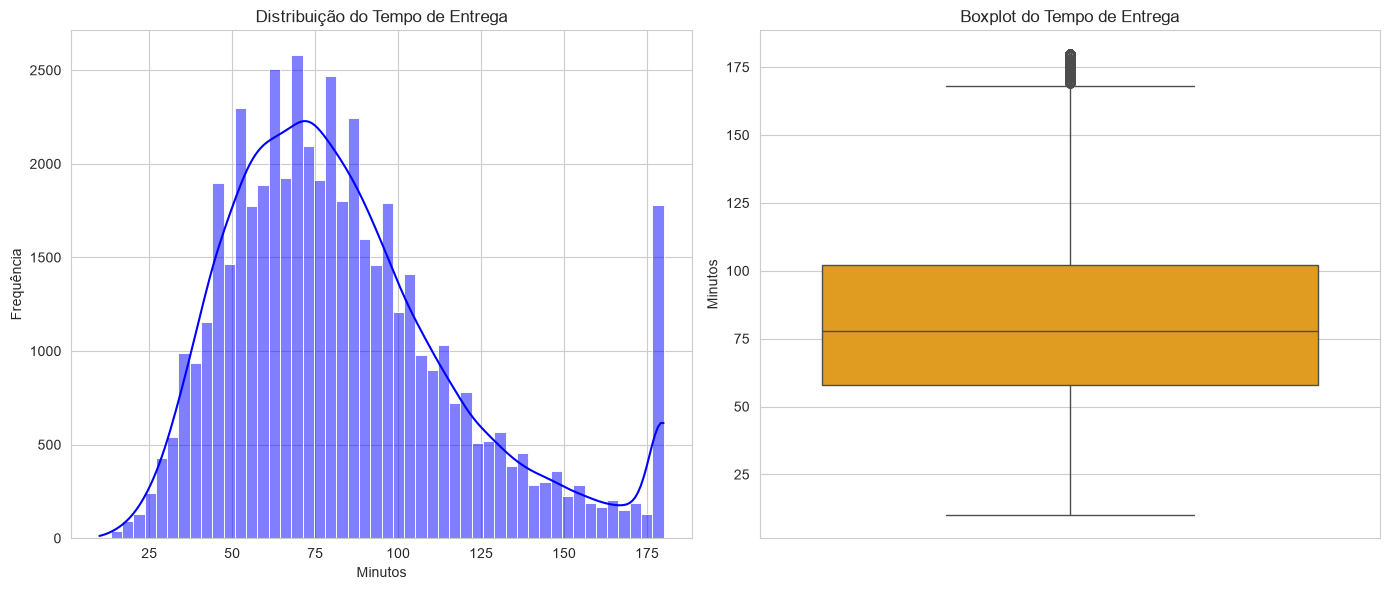

In [3]:
# Configurando o tamanho dos gráficos
plt.figure(figsize=(14, 6))

# 1. Gráfico da distribuição do tempo de entrega
plt.subplot(1, 2, 1)
sns.histplot(df['Time_taken_min'], bins=50, kde=True, color='blue')
plt.title('Distribuição do Tempo de Entrega')
plt.xlabel('Minutos')
plt.ylabel('Frequência')

# 2. Boxplot para ver se há outliers (valores muito fora do padrão)
plt.subplot(1, 2, 2)
sns.boxplot(y=df['Time_taken_min'], color='orange')
plt.title('Boxplot do Tempo de Entrega')
plt.ylabel('Minutos')

plt.tight_layout()
plt.show()

C:\Users\arthu\AppData\Local\Temp\ipykernel_24508\162178716.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Traffic_Level', y='Time_taken_min', palette='Set2')
C:\Users\arthu\AppData\Local\Temp\ipykernel_24508\162178716.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Weather', y='Time_taken_min', palette='Set3')


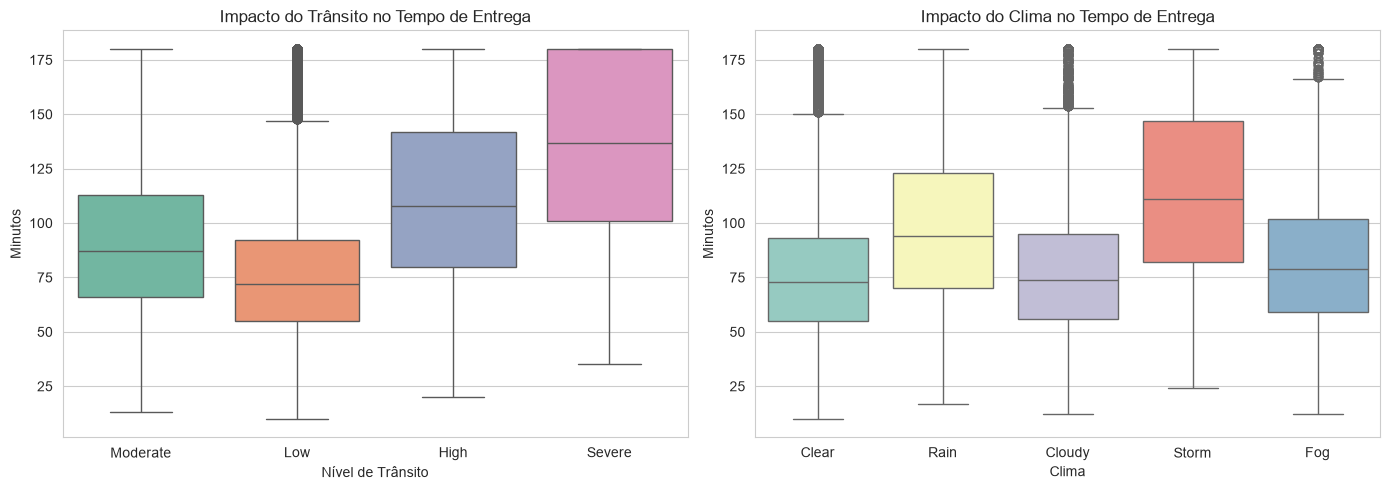

In [4]:
plt.figure(figsize=(14, 5))

# 1. Tempo de entrega por Nível de Trânsito
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='Traffic_Level', y='Time_taken_min', palette='Set2')
plt.title('Impacto do Trânsito no Tempo de Entrega')
plt.xlabel('Nível de Trânsito')
plt.ylabel('Minutos')

# 2. Tempo de entrega por Clima
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='Weather', y='Time_taken_min', palette='Set3')
plt.title('Impacto do Clima no Tempo de Entrega')
plt.xlabel('Clima')
plt.ylabel('Minutos')

plt.tight_layout()
plt.show()

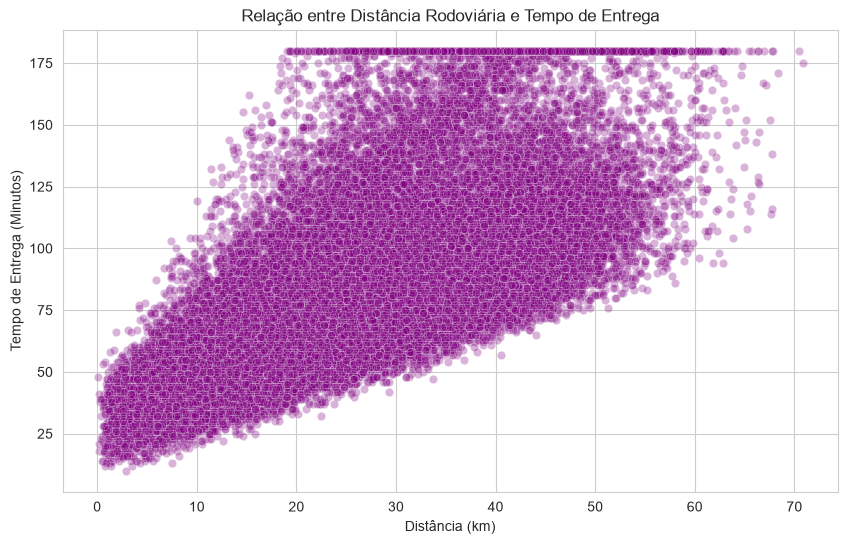

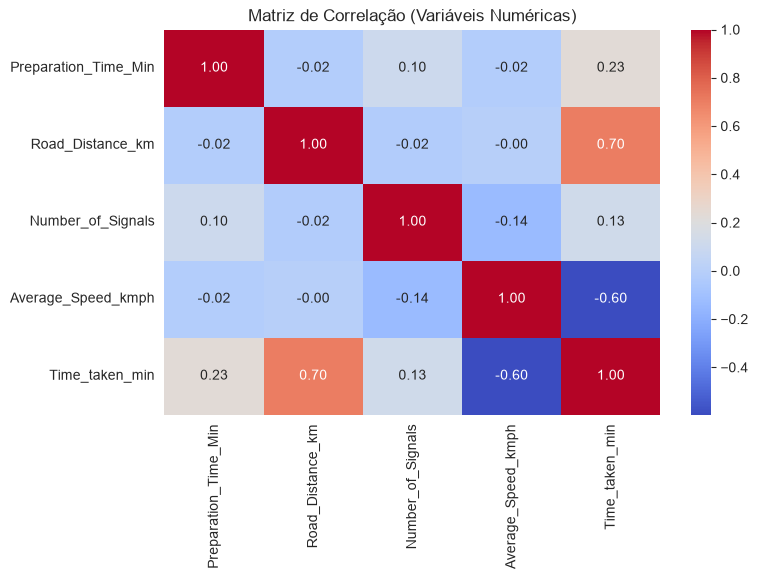

In [5]:
# Vamos analisar a relação entre a distância e o tempo
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='Road_Distance_km', y='Time_taken_min', alpha=0.3, color='purple')
plt.title('Relação entre Distância Rodoviária e Tempo de Entrega')
plt.xlabel('Distância (km)')
plt.ylabel('Tempo de Entrega (Minutos)')
plt.show()

# Vamos ver a matriz de correlação apenas das variáveis numéricas
# (Selecionei algumas que parecem importantes)
colunas_numericas = ['Preparation_Time_Min', 'Road_Distance_km', 'Number_of_Signals', 'Average_Speed_kmph', 'Time_taken_min']
plt.figure(figsize=(8, 5))
sns.heatmap(df[colunas_numericas].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlação (Variáveis Numéricas)')
plt.show()

In [6]:
# 1. Separar o alvo (y) das features (X)
y = df['Time_taken_min']

# 2. Criar o X, removendo o alvo e as colunas que causam vazamento de dados
# Dropamos também o Order_ID e Order_Date (que não são preditivos)
colunas_para_remover = ['Time_taken_min', 'Order_ID', 'Order_Date', 'Average_Speed_kmph', 'Delivery_Distance_Category']
X = df.drop(columns=colunas_para_remover)

# 3. Codificar variáveis categóricas (Textos viram números)
# O pd.get_dummies faz o One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)

# Ver como ficou o X final
print("Formato original do X:", X.shape)
print("Formato após One-Hot Encoding:", X_encoded.shape)
X_encoded.head()

Formato original do X: (50000, 19)
Formato após One-Hot Encoding: (50000, 46)


,Order_Hour,Is_Weekend,Is_Festival,Rider_Experience_Years,Rider_Rating,Restaurant_Rating,Order_Items,Preparation_Time_Min,Road_Distance_km,Number_of_Signals,...,Cuisine_Type_North Indian,Cuisine_Type_Pizza,Cuisine_Type_South Indian,Restaurant_Load_Low,Restaurant_Load_Medium,Traffic_Level_Low,Traffic_Level_Moderate,Traffic_Level_Severe,Delivery_Priority_Priority,Delivery_Priority_VIP
0,8,0,0,3.1,3.8,3.8,1,23,30.55,15,...,False,True,False,False,True,False,True,False,False,False
1,12,0,0,1.8,3.6,3.9,3,11,2.25,17,...,False,False,False,False,True,False,True,False,False,False
2,18,1,0,3.8,3.9,4.0,1,31,10.15,8,...,False,False,False,True,False,False,True,False,False,False
3,12,0,0,1.7,3.9,4.6,3,19,26.33,9,...,False,False,False,False,True,True,False,False,False,False
4,18,0,0,12.4,4.4,4.0,1,7,30.48,8,...,False,False,False,False,True,False,True,False,False,False


In [7]:
from sklearn.model_selection import train_test_split

# Separando os dados: 80% para treino, 20% para teste.
# random_state=42 garante que se você rodar de novo, a divisão será a mesma (reprodutibilidade)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print(f"Tamanho do treino: {X_train.shape[0]} pedidos")
print(f"Tamanho do teste: {X_test.shape[0]} pedidos")

Tamanho do treino: 40000 pedidos
Tamanho do teste: 10000 pedidos


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 1. Criar o modelo de Regressão Linear (baseline)
lr_model = LinearRegression()

# 2. Treinar o modelo com os dados de treino
lr_model.fit(X_train, y_train)

# 3. Fazer previsões nos dados de teste
y_pred_lr = lr_model.predict(X_test)

# 4. Calcular as métricas
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = root_mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("--- Regressão Linear (Baseline) ---")
print(f"MAE: {mae_lr:.2f} minutos")
print(f"RMSE: {rmse_lr:.2f} minutos")
print(f"R²: {r2_lr:.4f}")

--- Regressão Linear (Baseline) ---
MAE: 6.42 minutos
RMSE: 9.25 minutos
R²: 0.9326


In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Criar o modelo Random Forest
# n_estimators=100 significa que vamos criar 100 árvores de decisão
# n_jobs=-1 usa todos os núcleos do seu processador para ser mais rápido
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# 2. Treinar (isso pode demorar alguns segundos)
rf_model.fit(X_train, y_train)

# 3. Fazer previsões
y_pred_rf = rf_model.predict(X_test)

# 4. Calcular as métricas
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("--- Random Forest Regressor ---")
print(f"MAE: {mae_rf:.2f} minutos")
print(f"RMSE: {rmse_rf:.2f} minutos")
print(f"R²: {r2_rf:.4f}")

--- Random Forest Regressor ---
MAE: 3.09 minutos
RMSE: 4.12 minutos
R²: 0.9866


C:\Users\arthu\AppData\Local\Temp\ipykernel_24508\3853017384.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancia.head(15), x='Importancia', y='Feature', palette='viridis')


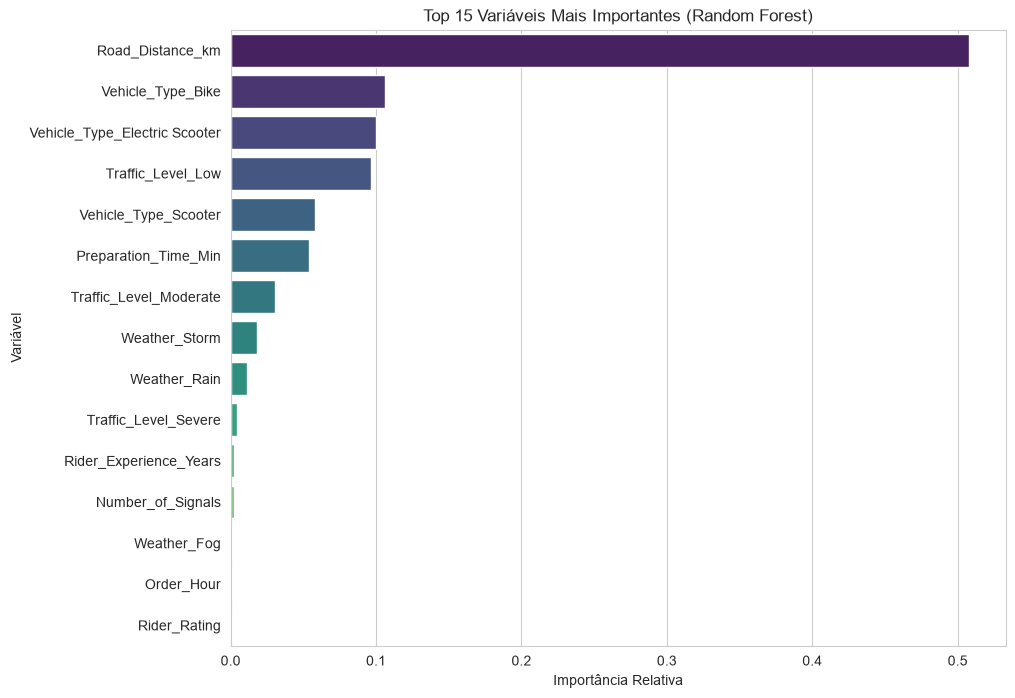

                          Feature  Importancia
8                Road_Distance_km     0.507582
28              Vehicle_Type_Bike     0.106135
29  Vehicle_Type_Electric Scooter     0.100011
41              Traffic_Level_Low     0.096351
30           Vehicle_Type_Scooter     0.057683
7            Preparation_Time_Min     0.053849
42         Traffic_Level_Moderate     0.030573
19                  Weather_Storm     0.018060
18                   Weather_Rain     0.011290
43           Traffic_Level_Severe     0.004515


In [11]:
# Obter a importância das features do modelo Random Forest
importancias = rf_model.feature_importances_

# Criar um DataFrame para visualizar melhor
df_importancia = pd.DataFrame({
    'Feature': X_train.columns,
    'Importancia': importancias
})

# Ordenar da mais importante para a menos importante
df_importancia = df_importancia.sort_values(by='Importancia', ascending=False)

# Mostrar as 15 mais importantes
plt.figure(figsize=(10, 8))
sns.barplot(data=df_importancia.head(15), x='Importancia', y='Feature', palette='viridis')
plt.title('Top 15 Variáveis Mais Importantes (Random Forest)')
plt.xlabel('Importância Relativa')
plt.ylabel('Variável')
plt.show()

# Imprimir a lista
print(df_importancia.head(10))

In [ ]:
def prever_tempo_entrega(distancia, clima, transito, veiculo, preparo, hora, experiencia):
    # 1. Cria um dicionário com os dados do pedido hipotético
    pedido = {
        'Order_Hour': [hora],
        'Is_Weekend': [0], # 0 para dia de semana
        'Is_Festival': [0],
        'Rider_Experience_Years': [experiencia],
        'Rider_Rating': [4.0], # assumindo nota média
        'Restaurant_Rating': [4.0],
        'Order_Items': [1],
        'Preparation_Time_Min': [preparo],
        'Road_Distance_km': [distancia],
        'Number_of_Signals': [10], # valor médio
        # Preenchemos as categóricas com o que o usuário passou
        'Weather': [clima],
        'Traffic_Level': [transito],
        'Vehicle_Type': [veiculo],
        'Cuisine_Type': ['North Indian'], # assumindo um padrão
        'Restaurant_Load': ['Medium'],
        'Delivery_Priority': ['Normal']
    }
    
    # 2. Transforma em DataFrame
    df_novo = pd.DataFrame(pedido)
    
    # 3. Aplica o mesmo One-Hot Encoding
    # IMPORTANTE: Precisamos garantir que o novo dado tenha as MESMAS colunas que o X_train
    df_novo_encoded = pd.get_dummies(df_novo)
    df_novo_encoded = df_novo_encoded.reindex(columns=X_train.columns, fill_value=0)
    
    # 4. Faz a previsão
    previsao = rf_model.predict(df_novo_encoded)[0]
    
    return previsao

# --- TESTANDO CENÁRIOS ---

# Cenário 1: Perto, limpo, trânsito baixo, scooter
c1 = prever_tempo_entrega(distancia=2.0, clima='Clear', transito='Low', veiculo='Scooter', preparo=10, hora=14, experiencia=5)

# Cenário 2: Mesma distância, mas com chuva e trânsito moderado
c2 = prever_tempo_entrega(distancia=2.0, clima='Rain', transito='Moderate', veiculo='Scooter', preparo=10, hora=14, experiencia=5)

# Cenário 3: Distância longa (15km), limpo, trânsito baixo
c3 = prever_tempo_entrega(distancia=15.0, clima='Clear', transito='Low', veiculo='Scooter', preparo=10, hora=14, experiencia=5)

# Cenário 4: Distância longa (15km), tempestade, trânsito severo
c4 = prever_tempo_entrega(distancia=15.0, clima='Storm', transito='Severe', veiculo='Bike', preparo=10, hora=14, experiencia=5)

print(f"Cenário 1 (2km, limpo): {c1:.1f} minutos")
print(f"Cenário 2 (2km, chuva): {c2:.1f} minutos")
print(f"Cenário 3 (15km, limpo): {c3:.1f} minutos")
print(f"Cenário 4 (15km, tempestade): {c4:.1f} minutos")

In [12]:
def prever_tempo_entrega(distancia, clima, transito, veiculo, preparo, hora, experiencia):
    # 1. Cria um dicionário com os dados do pedido hipotético
    pedido = {
        'Order_Hour': [hora],
        'Is_Weekend': [0], # 0 para dia de semana
        'Is_Festival': [0],
        'Rider_Experience_Years': [experiencia],
        'Rider_Rating': [4.0], # assumindo nota média
        'Restaurant_Rating': [4.0],
        'Order_Items': [1],
        'Preparation_Time_Min': [preparo],
        'Road_Distance_km': [distancia],
        'Number_of_Signals': [10], # valor médio
        # Preenchemos as categóricas com o que o usuário passou
        'Weather': [clima],
        'Traffic_Level': [transito],
        'Vehicle_Type': [veiculo],
        'Cuisine_Type': ['North Indian'], # assumindo um padrão
        'Restaurant_Load': ['Medium'],
        'Delivery_Priority': ['Normal']
    }
    
    # 2. Transforma em DataFrame
    df_novo = pd.DataFrame(pedido)
    
    # 3. Aplica o mesmo One-Hot Encoding
    # IMPORTANTE: Precisamos garantir que o novo dado tenha as MESMAS colunas que o X_train
    df_novo_encoded = pd.get_dummies(df_novo)
    df_novo_encoded = df_novo_encoded.reindex(columns=X_train.columns, fill_value=0)
    
    # 4. Faz a previsão
    previsao = rf_model.predict(df_novo_encoded)[0]
    
    return previsao

# --- TESTANDO CENÁRIOS ---

# Cenário 1: Perto, limpo, trânsito baixo, scooter
c1 = prever_tempo_entrega(distancia=2.0, clima='Clear', transito='Low', veiculo='Scooter', preparo=10, hora=14, experiencia=5)

# Cenário 2: Mesma distância, mas com chuva e trânsito moderado
c2 = prever_tempo_entrega(distancia=2.0, clima='Rain', transito='Moderate', veiculo='Scooter', preparo=10, hora=14, experiencia=5)

# Cenário 3: Distância longa (15km), limpo, trânsito baixo
c3 = prever_tempo_entrega(distancia=15.0, clima='Clear', transito='Low', veiculo='Scooter', preparo=10, hora=14, experiencia=5)

# Cenário 4: Distância longa (15km), tempestade, trânsito severo
c4 = prever_tempo_entrega(distancia=15.0, clima='Storm', transito='Severe', veiculo='Bike', preparo=10, hora=14, experiencia=5)

print(f"Cenário 1 (2km, limpo): {c1:.1f} minutos")
print(f"Cenário 2 (2km, chuva): {c2:.1f} minutos")
print(f"Cenário 3 (15km, limpo): {c3:.1f} minutos")
print(f"Cenário 4 (15km, tempestade): {c4:.1f} minutos")

Cenário 1 (2km, limpo): 18.2 minutos
Cenário 2 (2km, chuva): 20.4 minutos
Cenário 3 (15km, limpo): 40.5 minutos
Cenário 4 (15km, tempestade): 88.8 minutos


In [13]:
import joblib
import os

# Criar a pasta 'models' se ela não existir
os.makedirs('../models', exist_ok=True)

# Salvar o modelo treinado
joblib.dump(rf_model, '../models/random_forest_model.pkl')

# Salvar as colunas esperadas
joblib.dump(X_train.columns.tolist(), '../models/model_columns.pkl')

print("Modelo e colunas salvos com sucesso na pasta models/!")

Modelo e colunas salvos com sucesso na pasta models/!
